In [1]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
crop_df=pd.read_csv(r"C:\Users\user\Downloads\crop_yield.csv")

In [4]:
crop_df.head(10)

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
5,F006,Rice,2000.0,6.0,06/01/2023,Faisalabad,Rabi,Yes,40000
6,F007,Maize,1500.0,6.0,07/01/2023,Faisalabad,Rabi,No,30000
7,F008,Wheat,1500.0,5.0,08/01/2023,Lahore,Rabi,No,30000
8,F009,Wheat,2000.0,5.0,09/01/2023,Faisalabad,Rabi,Yes,40000
9,F010,Wheat,1500.0,3.0,10/01/2023,Faisalabad,Rabi,Yes,30000


In [5]:
crop_df.isnull().sum()

FARM_ID              0
CROP_TYPE            0
YIELD_KG           330
AREA_ACRES         144
HARVEST_DATE         0
DISTRICT           126
SEASON               0
FERTILIZER_USED    318
YIELD_VALUE          0
dtype: int64

In [7]:
crop_df.dtypes

FARM_ID                str
CROP_TYPE              str
YIELD_KG           float64
AREA_ACRES         float64
HARVEST_DATE           str
DISTRICT               str
SEASON                 str
FERTILIZER_USED        str
YIELD_VALUE          int64
dtype: object

In [8]:
crop_df.describe()

,YIELD_KG,AREA_ACRES,YIELD_VALUE
count,2670.000000,2856.000000,3000.000000
mean,2014.232210,4.420168,39657.780000
std,407.846962,0.979259,8405.078755
min,1500.000000,3.000000,20068.000000
25%,1500.000000,4.000000,30000.000000
50%,2000.000000,4.000000,40000.000000
75%,2500.000000,5.000000,50000.000000
max,2500.000000,6.000000,50000.000000


In [12]:
crop_df=crop_df.dropna(subset=["YIELD_KG"])

In [13]:
crop_df['AREA_ACRES'] = crop_df['AREA_ACRES'].fillna(crop_df['AREA_ACRES'].mean())

In [16]:
crop_df["FERTILIZER_USED"]=crop_df["FERTILIZER_USED"].fillna("No")

In [17]:
crop_df['DISTRICT'] = crop_df['DISTRICT'].fillna('Unknown')

In [21]:
crop_df['YIELD_VALUE'] = crop_df['YIELD_VALUE'].fillna(crop_df['YIELD_VALUE'].mean())

In [25]:
crop_df['HARVEST_DATE'] = pd.to_datetime(crop_df['HARVEST_DATE'], errors='coerce',format='%d/%m/%Y')

In [27]:
crop_df['FARM_ID'].str.replace('F', '').astype(int)

0          1
1          2
2          3
3          4
4          5
        ... 
2995    2996
2996    2997
2997    2998
2998    2999
2999    3000
Name: FARM_ID, Length: 2670, dtype: int64

In [28]:
crop_df.isnull().sum()

FARM_ID            0
CROP_TYPE          0
YIELD_KG           0
AREA_ACRES         0
HARVEST_DATE       0
DISTRICT           0
SEASON             0
FERTILIZER_USED    0
YIELD_VALUE        0
dtype: int64

In [29]:
crop_df.dtypes

FARM_ID                       str
CROP_TYPE                     str
YIELD_KG                  float64
AREA_ACRES                float64
HARVEST_DATE       datetime64[us]
DISTRICT                      str
SEASON                        str
FERTILIZER_USED               str
YIELD_VALUE                 int64
dtype: object

In [33]:
total_yield = crop_df.groupby('CROP_TYPE').agg({'YIELD_KG': 'sum'}).reset_index()

In [35]:
total_yield

,CROP_TYPE,YIELD_KG
0,Maize,1112500.0
1,Rice,1638000.0
2,Sugarcane,592000.0
3,Wheat,2035500.0


In [49]:
x = x = total_yield['CROP_TYPE']
y = total_yield['YIELD_KG'].values

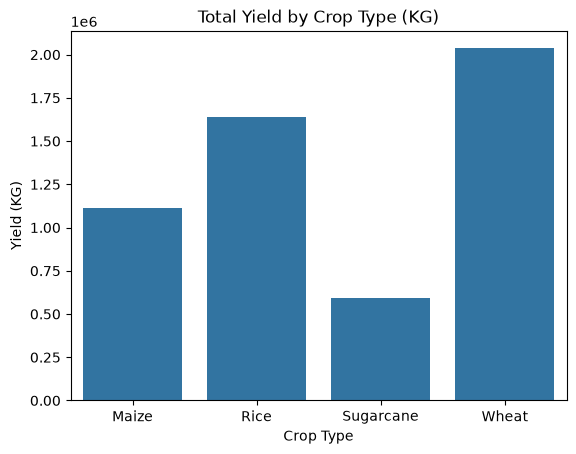

In [50]:
sns.barplot(x=x, y=y)
plt.title('Total Yield by Crop Type (KG)')
plt.ylabel('Yield (KG)')
plt.xlabel('Crop Type')
plt.show()

In [45]:
pivot_yield = crop_df.pivot_table(values='YIELD_KG', index='HARVEST_DATE', aggfunc='sum')
pivot_yield

,YIELD_KG
HARVEST_DATE,
2023-01-01,1500.0
2023-01-02,1500.0
2023-01-03,2500.0
2023-01-04,1500.0
2023-01-05,1500.0
...,...
2031-03-15,1500.0
2031-03-16,2000.0
2031-03-17,2000.0


In [69]:
yearly_pivot = crop_df.pivot_table(values='YIELD_KG', index=crop_df['HARVEST_DATE'].dt.year, aggfunc='sum')
yearly_yield

HARVEST_DATE
2023    663500.0
2024    640500.0
2025    660000.0
2026    654500.0
2027    672000.0
2028    657000.0
2029    635500.0
2030    653000.0
2031    142000.0
Name: YIELD_KG, dtype: float64

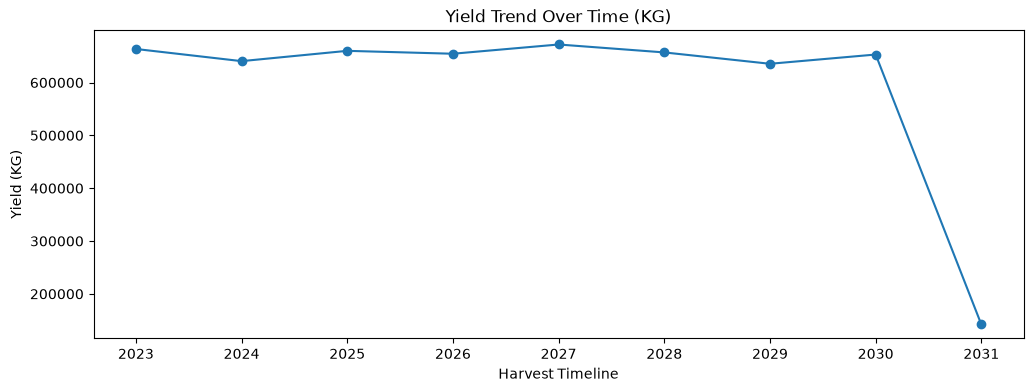

In [70]:
x = yearly_yield.index
y = yearly_yield.values
plt.figure(figsize=(12,4))
plt.plot(x, y,marker='o')
plt.title('Yield Trend Over Time (KG)')
plt.ylabel('Yield (KG)')
plt.xlabel('Harvest Timeline')
plt.savefig('crop_yield_trend.png')
plt.show()